# Exploratory Data Analysis (EDA) on Global Video Game Sales
## Setup, Library Imports, and Initial Data Inspection
This section imports the data science libraries, loads the video game sales dataset, and inspects its initial structure.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context("talk", font_scale=0.8)  # bigger text

try:
    df = pd.read_csv("vgsales.csv")
    print(f"Dataset successfully loaded. Total rows: {df.shape[0]}, Total columns: {df.shape[1]}")
except FileNotFoundError:
    raise SystemExit("Warning: 'vgsales.csv' not found in the current directory. Please upload the file to proceed.")
except Exception as e:
    raise SystemExit(f"An unexpected error occurred while reading the file: {e}")

# Preview the first 5 rows
display(df.head())

Dataset successfully loaded. Total rows: 16598, Total columns: 11


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## Data Cleaning and Validation
This section checks the dataset for duplicate rows and missing values, fixes the ranking index, and creates the cleaned dataset (`df_clean`).

In [7]:
# Data cleaning and checking for uncleaned values

# Rank = index + 1 (the data skips some row numbers)
df["Rank"] = df.index + 1

# Count duplicate rows (Rank is unique, so ignore it)
duplicates_count = df.drop(columns="Rank").duplicated().sum()
# Rows with at least one missing value
missing_rows = df[df.isna().any(axis=1)]
# Drop rows with missing values, reset the index
df_clean = df.dropna().reset_index(drop=True)

assert df_clean.isna().sum().sum() == 0, "df_clean still has missing values"
assert len(df_clean) == len(df) - len(missing_rows), "Unexpected row count"

print(f"{duplicates_count} duplicate rows")
print(f"{len(missing_rows)} rows with missing values")
print(f"{len(df_clean):,} rows in df_clean")

1 duplicate rows
307 rows with missing values
16,291 rows in df_clean


## Topic 1: Regional Sales Analysis and Global Sales Statistics
This section shows the top 3 best-selling games in North America, Europe and Japan, and computes global sales statistics.

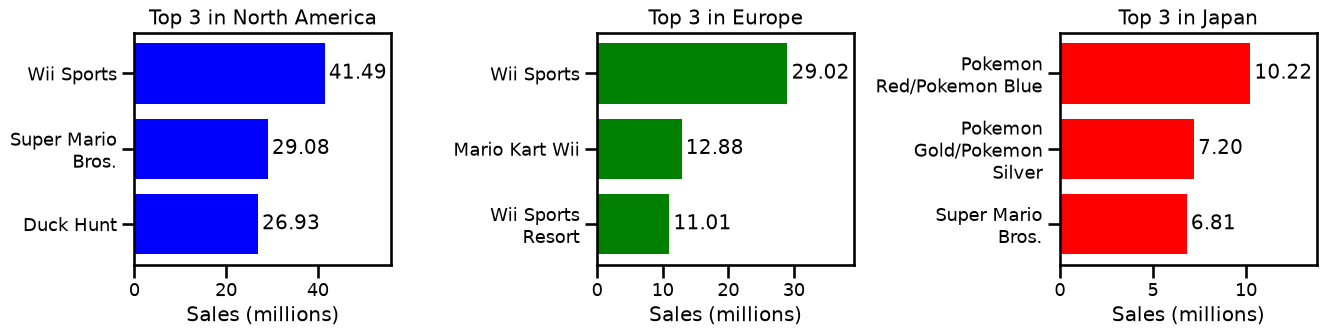

In [5]:
# The first topic

# Three bar charts: top 3 games in each region
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
regions_data = [
    ("NA_Sales", "North America", "blue"),
    ("EU_Sales", "Europe", "green"),
    ("JP_Sales", "Japan", "red"),
]
for ax, (col, title, color) in zip(axes, regions_data):
    top_games = df_clean.nlargest(3, col)
    ax.barh(top_games["Name"].str.wrap(16), top_games[col], color=color)
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
    ax.set_title(f"Top 3 in {title}")
    ax.set_xlabel("Sales (millions)")
    ax.invert_yaxis()
    ax.margins(x=0.35)
plt.tight_layout()
plt.show()

## Topic 2: Market Concentration & Top 10% Sales Threshold
This section calculates the 90th percentile sales threshold to evaluate market concentration.

Top 10% Sales Threshold: 1.22M units
Total games in this top 10% group: 1633

This shows that the videogames market is highly competitive.


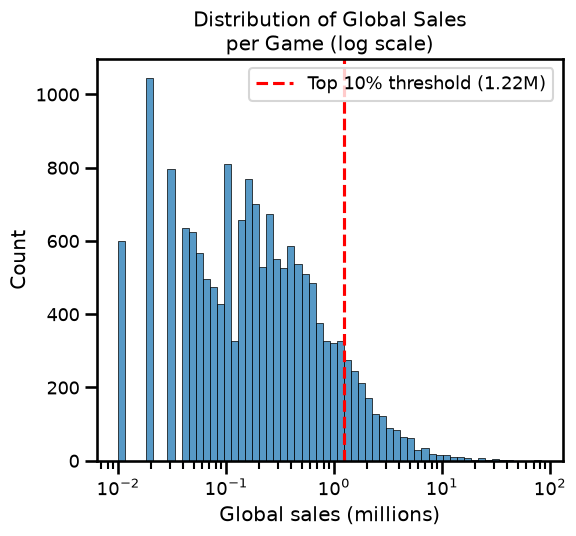

In [4]:
# The second topic

global_sales = df_clean['Global_Sales'].to_numpy()
top_10_threshold = np.percentile(global_sales, 90)                # Finding the top 10 % videogames
top_tier_sales = global_sales[global_sales >= top_10_threshold]   # Filter the games using a boolean mask

print(f"""Top 10% Sales Threshold: {top_10_threshold:.2f}M units
Total games in this top 10% group: {len(top_tier_sales)}

This shows that the videogames market is highly competitive.""")

# Data visualization 

plt.figure(figsize=(6, 5.6))                                       # Modifying and illustrating the chart 
sns.histplot(df_clean["Global_Sales"], bins=60, log_scale=True)
plt.axvline(top_10_threshold, color="red", linestyle="--", label=f"Top 10% threshold ({top_10_threshold:.2f}M)")
plt.title("Distribution of Global Sales\nper Game (log scale)")
plt.xlabel("Global sales (millions)")
plt.legend()
plt.tight_layout()
plt.show()

## Topic 3: Regional Sales Correlation Analysis
This section computes the correlation coefficient matrix across regional markets.

This chart shows that NA and EU have almost the same taste in video games, while Japan has a unique market, having the smallest correlation coefficient with every other region:



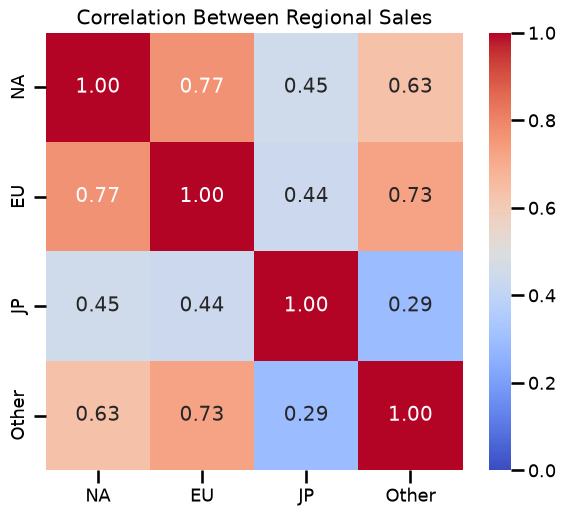

In [5]:
# The third topic

regional_data = df_clean[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].to_numpy().T      # .T for np.corrcoef to generate a 4x4 matrix
corr_matrix = np.corrcoef(regional_data)                                                  # Creating a correlation matrix
regions = ['NA', 'EU', 'JP', 'Other']
corr_df = pd.DataFrame(corr_matrix, index=regions, columns=regions)                       # A dataframe created out of corr_matrix

# Data Visualization 

plt.figure(figsize=(6, 5.4))                                                                # Modifying and illustrating the chart
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1)
plt.title("Correlation Between Regional Sales")
plt.tight_layout()
print("This chart shows that NA and EU have almost the same taste in video games, while Japan has a unique market, having the smallest correlation coefficient with every other region:\n")
plt.show()

## Topic 4: Console Wars: Sales by Console Maker
This section compares the total historical sales of Sony, Microsoft and Nintendo.

This shows that Nintendo and Sony are the historical leaders of the videogame market, leaving Microsoft in third place.



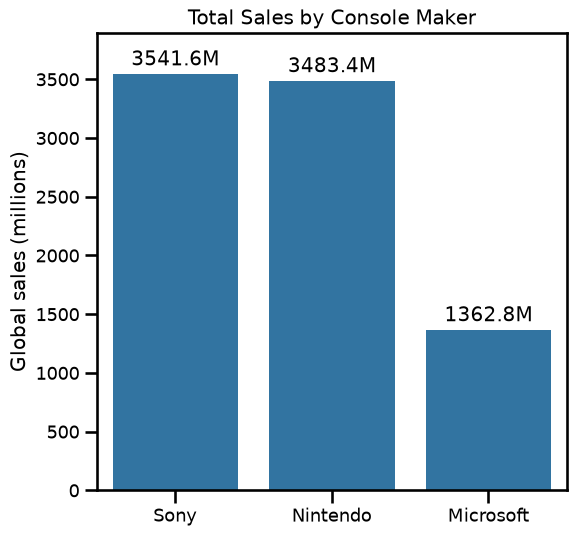

In [6]:
# Topic 4: Console Wars — Comparing historical game sales by hardware manufacturer

# Group consoles and handhelds under their respective parent companies
companies = {
    "Sony":      ["PS", "PS2", "PS3", "PS4", "PSP", "PSV"],
    "Microsoft": ["XB", "X360", "XOne"],
    "Nintendo":  ["NES", "SNES", "N64", "GC", "Wii", "WiiU", "GB", "GBA", "DS", "3DS"]
}

# Invert the dictionary using a nested comprehension so each platform maps to its company
platform_map = {p: company for company, platforms in companies.items() for p in platforms}

# Aggregate global sales by console maker and rank from highest to lowest
console_wars = (
    df_clean["Global_Sales"]
    .groupby(df_clean["Platform"].map(platform_map).rename("Company"))  # Unmapped platforms (e.g., PC) become NaN and are excluded
    .sum()                                                              # Sum sales across all titles per company
    .sort_values(ascending=False)                                       # Sort descending for the bar chart
)

# Print key takeaway before displaying the visual
print("This shows that Nintendo and Sony are the historical leaders of the videogame market, leaving Microsoft in third place.\n")

# Create and configure the bar chart
plt.figure(figsize=(6, 5.6))
ax = sns.barplot(x=console_wars.index, y=console_wars.values)
ax.bar_label(ax.containers[0], fmt="%.1fM", padding=3)    # Exact value (in millions) on top of each bar
ax.margins(y=0.1)                                          # Headroom so the labels fit inside the plot
plt.title("Total Sales by Console Maker")
plt.ylabel("Global sales (millions)")
plt.xlabel("") 
plt.tight_layout()
plt.show()

## Topic 5: Publisher Dependency on Flagship Franchises
This section measures what share of a publisher's total sales comes from its flagship franchise.


This plot shows that even the biggest publishers heavily rely on a single core franchise, which can account for a massive portion of their entire historical revenue.



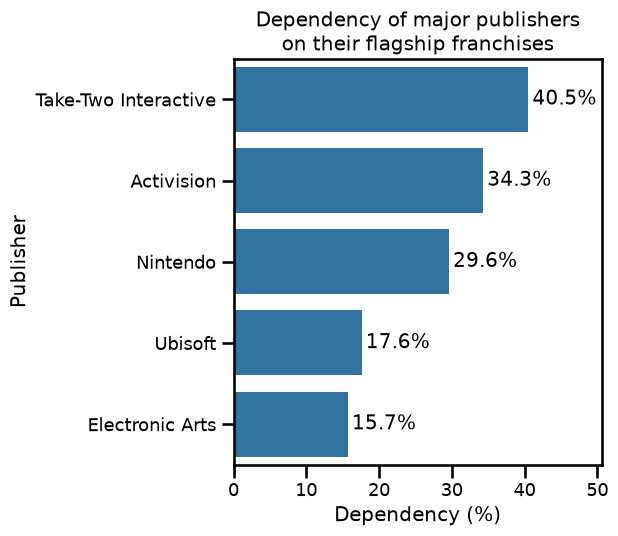

In [7]:
# Topic 5: Publisher Dependency — Measuring how heavily major publishers rely on a single flagship franchise

def get_franchise_dependency(df, publisher, franchise):
    """Calculates total sales and percentage dependency on a specific franchise for a given publisher."""
    # Filter the dataset for all games released by the target publisher and sum their global sales
    pub_data = df[df['Publisher'] == publisher]
    pub_total = pub_data['Global_Sales'].sum()

    # Search game titles for the franchise keyword (case-insensitive, ignoring NaNs) and sum those sales
    fran_data = pub_data[pub_data['Name'].str.contains(franchise, case=False, na=False)]
    fran_total = fran_data['Global_Sales'].sum()

    # Compute the franchise's percentage share of the publisher's total sales (guarding against division by zero)
    dependency = (fran_total / pub_total * 100) if pub_total > 0 else 0

    return {
        'Publisher': publisher,
        'Dependency_%': round(dependency, 1)
    }


# 1. Define target pairs of (Publisher, Flagship Franchise) to evaluate

franchises_to_check = [
    ('Take-Two Interactive', 'Grand Theft Auto'),
    ('Electronic Arts', 'FIFA'),
    ('Activision', 'Call of Duty'),
    ('Ubisoft', "Assassin's Creed"),
    ('Nintendo', 'Mario')
]

# 2. Compute dependency metrics for each pair using a list comprehension
results = [get_franchise_dependency(df_clean, pub, fran) for pub, fran in franchises_to_check]

# 3. Convert results into a DataFrame, rank from highest to lowest dependency
dependency_df = pd.DataFrame(results).sort_values(by='Dependency_%', ascending=False)

# Print key takeaway before displaying the visual
print("\nThis plot shows that even the biggest publishers heavily rely on a single core franchise, which can account for a massive portion of their entire historical revenue.\n")

# Create and configure the horizontal bar chart
plt.figure(figsize=(6.4, 5.6))
ax = sns.barplot(data=dependency_df, x="Dependency_%", y="Publisher")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)   # Exact percentage at the end of each bar
ax.margins(x=0.25)                                         # Room on the right so the labels fit inside the plot
plt.title("Dependency of major publishers\non their flagship franchises")
plt.xlabel("Dependency (%)")
plt.tight_layout()
plt.show()

## Topic 6: Sales by Console Generation
This section groups platforms into console generations to see which era was the most commercially successful.

In [1]:
# Topic 6: Sales by Console Generation — Comparing total and average commercial performance across hardware eras

# Map each platform code to its historical console generation (grouping handhelds and PC separately)
gen_map = {
    "NES": "Gen 3-4 (8/16-bit)", "SNES": "Gen 3-4 (8/16-bit)", "GEN": "Gen 3-4 (8/16-bit)",
    "PS": "Gen 5 (32/64-bit)",   "N64": "Gen 5 (32/64-bit)",   "SAT": "Gen 5 (32/64-bit)",
    "PS2": "Gen 6 (128-bit)",    "XB": "Gen 6 (128-bit)",      "GC": "Gen 6 (128-bit)",   "DC": "Gen 6 (128-bit)",
    "PS3": "Gen 7 (HD Era)",     "X360": "Gen 7 (HD Era)",     "Wii": "Gen 7 (HD Era)",
    "PS4": "Gen 8 (Modern)",     "XOne": "Gen 8 (Modern)",     "WiiU": "Gen 8 (Modern)",
    "GB": "Handheld", "GBA": "Handheld", "DS": "Handheld", "3DS": "Handheld",
    "PSP": "Handheld", "PSV": "Handheld",
    "PC": "PC",
}

# Aggregate total sales, and average sales per title for each era
generations_df = (
    df_clean
    .assign(Generation=df_clean["Platform"].map(gen_map))       # Create a temporary Generation column (unmapped retro platforms become NaN and are excluded)
    .groupby("Generation")
    .agg(
        Total_Sales_M=("Global_Sales", "sum"),                  # Total copies sold across the entire era
        Mean_Sales_M=("Global_Sales", "mean"),                  # Average copies sold per game release
    )
    .sort_values(by="Total_Sales_M", ascending=False)           # Rank generations by total global sales
    .reset_index()
)

# Extract the top-performing era dynamically and print key takeaway
top_gen = generations_df.iloc[0]["Generation"]
print(f"The plots show that {top_gen} is the most commercially successful era in the dataset.")

# Plot 1: Total sales volume per generation
plt.figure(figsize=(6, 5.6))
ax = sns.barplot(data=generations_df, x="Total_Sales_M", y="Generation")
ax.set_title("Total Sales by Generation")
ax.set_xlabel("Millions of copies")
ax.bar_label(ax.containers[0], fmt="%.1fM", padding=3)    # Exact value at the end of every bar
ax.margins(x=0.35)                                        # Room on the right so the labels fit inside the plot
plt.tight_layout()
plt.show()

# Plot 2: Average sales per title (shows per-game efficiency rather than library size)
plt.figure(figsize=(6, 5.6))
ax = sns.barplot(data=generations_df, x="Mean_Sales_M", y="Generation")
ax.set_title("Average Sales per Game by Generation")
ax.set_xlabel("Millions of copies")
ax.bar_label(ax.containers[0], fmt="%.2fM", padding=3)
ax.margins(x=0.35)
plt.tight_layout()
plt.show()

NameError: name 'df_clean' is not defined

## Topic 7: Major Publisher Profiles
This section builds a profile for each major publisher: total sales, best-selling game, top genre and top region.

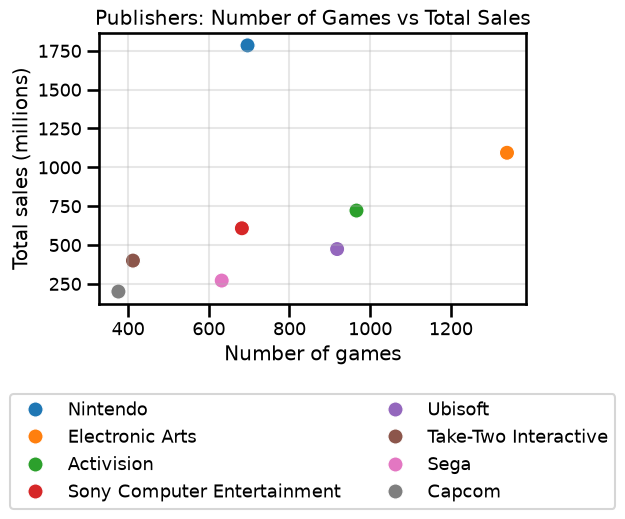


Publisher market conclusion
1. Market Leadership: Nintendo dominates the industry with the highest total sales (1784.43M units), driven heavily by massive hits like Wii Sports (Wii, 82.74M).
2. Portfolio Efficiency: Nintendo stands out as the most efficient publisher, averaging 2.56M copies per game due to consistently high-performing franchises.
3. Regional Focus: The dominant market across major publishers remains North America, which accounts for the largest share of historical sales for these industry leaders.


The plot and conclusion are referencing to this table:


,Publisher,Total_Sales_M,Games_Count,Mean_Sales_M,Top_Game,Top_Genre,Top_Region
1,Nintendo,1784.43,696,2.56,"Wii Sports (Wii, 82.74M)",Platform,NA (46%)
2,Electronic Arts,1093.39,1339,0.82,"FIFA 16 (PS4, 8.49M)",Sports,NA (53%)
3,Activision,721.41,966,0.75,"Call of Duty: Modern Warfare 3 (X360, 14.76M)",Shooter,NA (59%)
4,Sony Computer Entertainment,607.28,682,0.89,"Gran Turismo 3: A-Spec (PS2, 14.98M)",Racing,NA (44%)
5,Ubisoft,473.54,918,0.52,"Just Dance 3 (Wii, 10.26M)",Action,NA (53%)
6,Take-Two Interactive,399.30,412,0.97,"Grand Theft Auto V (PS3, 21.4M)",Action,NA (55%)
7,Sega,270.70,632,0.43,"Mario & Sonic at the Olympic Games (Wii, 8.06M)",Sports,NA (40%)
8,Capcom,199.95,376,0.53,"Street Fighter II: The World Warrior (SNES, 6.3M)",Action,NA (39%)


In [9]:
# Topic 7: Major Publisher Profiles — Comparing sales volume, release count, and efficiency across top publishers

# Define the list of major publishers to evaluate
publishers_to_check = [
    'Nintendo', 'Electronic Arts', 'Activision', 'Ubisoft',
    'Take-Two Interactive', 'Sony Computer Entertainment', 'Sega', 'Capcom'
]

# Initialize a list to store one summary dictionary per publisher
rows = []

for pub in publishers_to_check:
    # Filter the dataset for all games released by the current publisher
    pub_data = df_clean[df_clean['Publisher'] == pub]

    # Compute total global sales (in millions) and total number of game releases
    total_sales = pub_data['Global_Sales'].sum()
    games_count = len(pub_data)

    # Locate the row with the publisher's highest-selling individual game
    top_row = pub_data.loc[pub_data['Global_Sales'].idxmax()]

    # Group by genre, sum global sales, and extract the top-performing genre name
    top_genre = pub_data.groupby('Genre')['Global_Sales'].sum().idxmax()

    # Sum sales across all four regions and calculate the leading region's percentage share
    regions = pub_data[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].sum()
    top_region = regions.idxmax().replace('_Sales', '')
    top_region_share = regions.max() / regions.sum() * 100

    # Append compiled publisher metrics to the rows list
    rows.append({
        'Publisher': pub,
        'Total_Sales_M': round(total_sales, 2),
        'Games_Count': games_count,
        'Mean_Sales_M': round(total_sales / games_count, 2),
        'Top_Game': f"{top_row['Name']} ({top_row['Platform']}, {top_row['Global_Sales']}M)",
        'Top_Genre': top_genre,
        'Top_Region': f"{top_region} ({top_region_share:.0f}%)"
    })

# Convert to a DataFrame, sort by total global sales, and shift index to start at 1
publishers_df = (
    pd.DataFrame(rows)
    .sort_values(by='Total_Sales_M', ascending=False)
    .reset_index(drop=True)
)
publishers_df.index += 1

# Identify the leader in total volume and the leader in average sales per game
top_total = publishers_df.iloc[0]
top_mean = publishers_df.sort_values(by='Mean_Sales_M', ascending=False).iloc[0]

# Plot release count vs. total sales to compare quantity-driven vs. efficiency-driven publishers
plt.figure(figsize=(6.2, 6))
sns.scatterplot(data=publishers_df, x="Games_Count", y="Total_Sales_M",
                hue="Publisher", s=120)

plt.title("Publishers: Number of Games vs Total Sales")
plt.xlabel("Number of games")
plt.ylabel("Total sales (millions)")
plt.legend(bbox_to_anchor=(0.5, -0.3), loc="upper center", ncol=2, fontsize=13)   # Place legend below the plot area
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print dynamic insights summarizing volume leadership, per-game efficiency, and regional dominance
print(f"""\nPublisher market conclusion
1. Market Leadership: {top_total['Publisher']} dominates the industry with the highest total sales ({top_total['Total_Sales_M']}M units), driven heavily by massive hits like {top_total['Top_Game']}.
2. Portfolio Efficiency: {top_mean['Publisher']} stands out as the most efficient publisher, averaging {top_mean['Mean_Sales_M']}M copies per game due to consistently high-performing franchises.
3. Regional Focus: The dominant market across major publishers remains North America, which accounts for the largest share of historical sales for these industry leaders.
""")

# Display the full summary table for reference
print("\nThe plot and conclusion are referencing to this table:")
display(publishers_df)